**GitHub Repository:** https://github.com/2026545-git/Statistical-techniques-Sept26-CA2

**Video Recording Link:**

# Statistical Analysis of Supermarket Sales

**Module:** Statistical Techniques for Data Analysis

**Assessment:** CA2

**Dataset:** Supermarket sales

**Student Name:** Ankhjargal Tsogtjargal

**Student ID:** 2026545

## 1. Introduction

This study focuses on supermarket sales in Myanmar. The dataset includes sales from three branches in Yangon, Mandalay and Naypyitaw between January and March 2019.

The dataset contains 1,000 sales transactions and 17 variables.

The aim of this study is to understand customer behaviour and sales patterns. Descriptive statistics, graphs, confidence intervals and statistical tests will be used to analyse the data.

The results may help supermarket managers understand their customers and make better business decisions.

## 2. Data Loading and Preparation

In [9]:
# Import the required libraries for statistical analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [4]:
# Load the supermarket sales dataset
df = pd.read_csv("1000-Supermarket-Sales.csv")

# Display the first five rows
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [5]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names and data types
df.info()

Dataset shape: (1000, 17)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   str    
 1   Branch                   1000 non-null   str    
 2   City                     1000 non-null   str    
 3   Customer type            1000 non-null   str    
 4   Gender                   1000 non-null   str    
 5   Product line             1000 non-null   str    
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   str    
 11  Time                     1000 non-null   str    
 12  Payment                  1000 non-null   str    
 13  cogs                     1000 non-null   float64
 14  gross marg

In [8]:
# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Missing values:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64
Duplicate rows: 0


## Initial Data Quality Assessment

The dataset contains 1,000 rows and 17 columns. It includes both categorical and numerical variables.

The initial data quality checks found no missing values and no duplicate rows. Therefore, no rows need to be removed for these two reasons. Further checks will be performed before the statistical analysis.

## 3. Descriptive Statistics

Descriptive statistics help us understand the main
features of the dataset, such as the average,
spread and range of numerical values.

In [11]:
# Select the main numerical variables
numerical_columns = ['Unit price', 'Quantity', 'Total', 'Rating']

# Display descriptive statistics
df[numerical_columns].describe()

,Unit price,Quantity,Total,Rating
count,1000.000000,1000.000000,1000.000000,1000.00000
mean,55.672130,5.510000,322.966749,6.97270
std,26.494628,2.923431,245.885335,1.71858
min,10.080000,1.000000,10.678500,4.00000
25%,32.875000,3.000000,124.422375,5.50000
50%,55.230000,5.000000,253.848000,7.00000
75%,77.935000,8.000000,471.350250,8.50000
max,99.960000,10.000000,1042.650000,10.00000


### Interpretation of Numerical Variables

The average unit price is 55.67. Customers buy around 5 to 6 items per transaction.

The average total spending is 322.97, while the median is 253.85. This suggests that some high spending transactions may increase the mean.

The average customer rating is 6.97 out of 10. The ratings range from 4 to 10.

In [13]:
# Select categorical variables
categorical_columns = ['Branch', 'Customer type', 'Gender','Product line', 'Payment']

# Display categorical statistics
df[categorical_columns].describe()

,Branch,Customer type,Gender,Product line,Payment
count,1000,1000,1000,1000,1000
unique,3,2,2,6,3
top,A,Member,Female,Fashion accessories,Ewallet
freq,340,501,501,178,345


### Interpretation of Categorical Variables

Branch A has the highest number of transactions (340).

There are 501 member transactions and 499 normal customer transactions. The gender groups are also almost equal.

Fashion accessories is the most common product category with 178 transactions. E-wallet is the most common payment method with 345 transactions.

## 4. Data Visualisation

### 4.1 Distribution of Total Spending

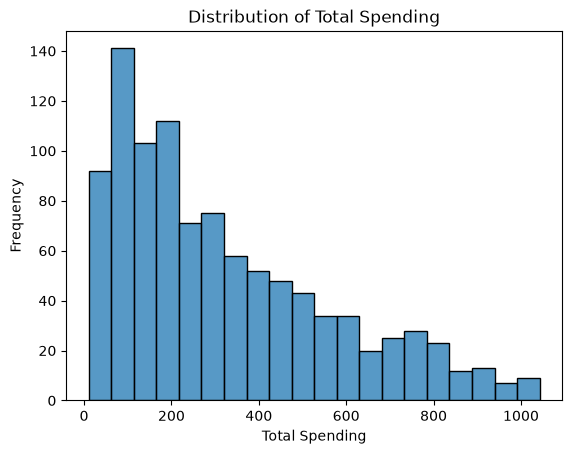

In [14]:
# Display the distribution of total spending
sns.histplot(df['Total'], bins=20)
plt.title('Distribution of Total Spending')
plt.xlabel('Total Spending')
plt.ylabel('Frequency')
plt.show()

The histogram shows a right-skewed distribution. Lower spending transactions are more common, while high spending transactions are less common.

The mean (322.97) is higher than the median (253.85). The data does not appear to follow a normal distribution. A normality test will be used to check this.

### 4.2 Distribution of Customer Ratings

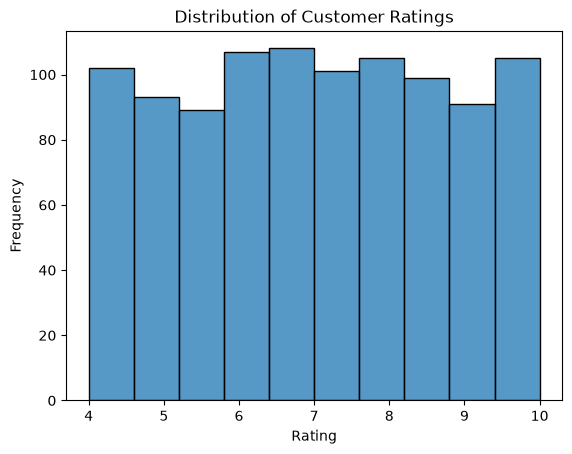

In [15]:
# Display the distribution of customer ratings
sns.histplot(df['Rating'], bins=10)
plt.title('Distribution of Customer Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

The histogram shows an approximately uniform distribution. Customer ratings are spread fairly evenly between 4 and 10.

The mean (6.97) and median (7.00) are very close. However, the distribution does not have a bell shape.

### 4.3 Number of Transactions by Branch

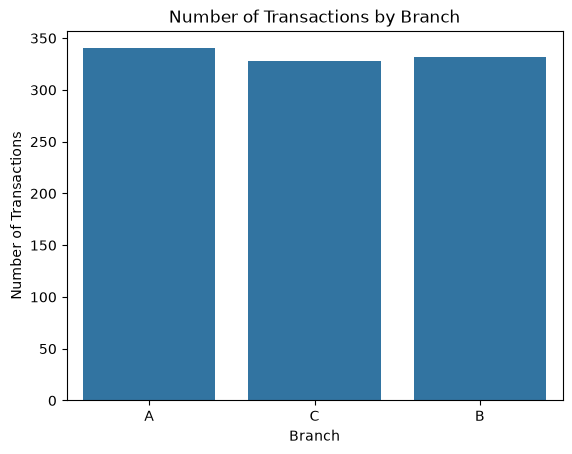

In [17]:
# Display the number of transactions by branch
sns.countplot(x='Branch', data=df)
plt.title('Number of Transactions by Branch')
plt.xlabel('Branch')
plt.ylabel('Number of Transactions')
plt.show()

The bar chart shows that the three branches have a similar number of transactions. Branch A has the highest number of transactions, while Branch C has the lowest.

However, the difference between the three branches is small.

### 4.4 Total Spending by Customer Type

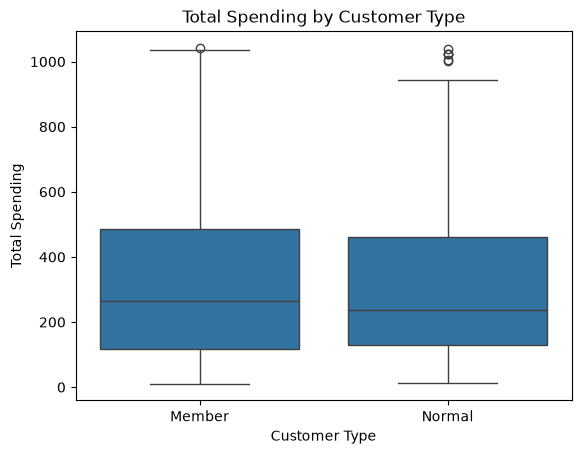

In [19]:
# Compare total spending by customer type
sns.boxplot(x='Customer type', y='Total', data=df)
plt.title('Total Spending by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Total Spending')
plt.show()

The boxplot shows that members have a slightly higher median spending than normal customers.

Both groups have a similar spread, and some high spending outliers can be seen.

A statistical test is needed to check if the difference between the two groups is significant.

### 4.5 Number of Transactions by Payment Method

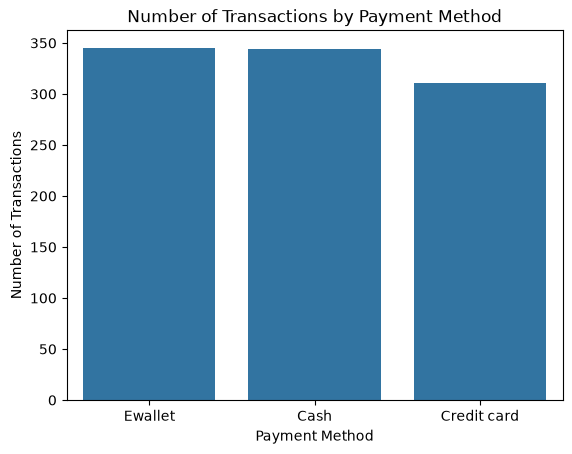

In [20]:
# Display the most common payment methods
sns.countplot(x='Payment', data=df)
plt.title('Number of Transactions by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Transactions')
plt.show()

The bar chart shows that E-wallet and cash are almost equally popular. Credit card is the least used payment method.

However, the difference between the three payment methods is small. This suggests that supermarkets should continue to offer all three payment options.

### 4.6 Total Spending by Branch 

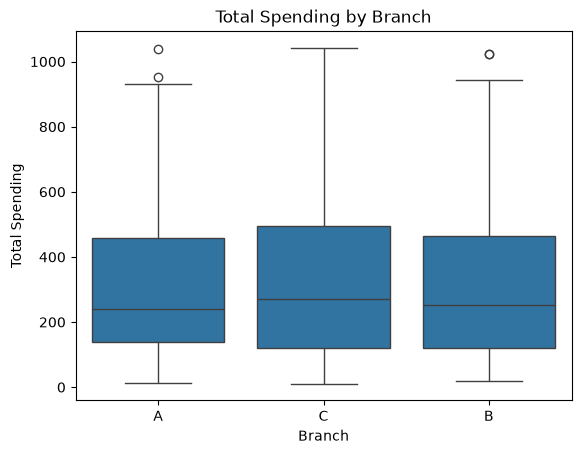

In [21]:
# Compare total spending across branches
sns.boxplot(x='Branch', y='Total', data=df)
plt.title('Total Spending by Branch')
plt.xlabel('Branch')
plt.ylabel('Total Spending')
plt.show()

Branch C has the highest median spending, while Branch A has the lowest. The spending distribution is similar across the three branches.

Some high spending outliers can be seen in Branch A and Branch B. A statistical test is needed to check if the differences between branches are significant.